<center>
    
    COMP5435 - Reinforcement Learning
    
# Temporal Difference

    
</center>

Student Name: Matthew Jarek 

The purpose of this project is to study different properties of Temporal Difference methods.  

**General Notes:**
- Questions marked with * are optional for COMP4240 - Undergraduate section. However, students in COMP4240 can gain some extra credits by solving the last part. Questions marked as extra credit are optional for everyone. 
- Do not use a mix of python lists and numpy arrays. Every vector or matrix in your code should be a numpy array. 
- For functions that exist in both the python core and the numpy library, use the one in the numpy library. For example, use `np.max` instead of `max`. Another example: use `np.random.normal` instead of `random.gauss`.
- Make sure all of your plots have a proper size and include `xlabel`, `ylabel`, `legend`, `title`, and `grid`.

In [1]:
# You are allowed to use the following modules
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

np.random.seed(0)


/home/matthew/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Using Cliff Walking from gym

This environment is part of the Toy Text environments which contains general information about the environment. Cliff walking involves crossing a gridworld from start to goal while avoiding falling off a cliff.


**Description**

The game starts with the player at location $[3, 0]$ of the 4x12 grid world with the goal located at $[3, 11]$. If the player reaches the goal the episode ends. A cliff runs along $[3, 1..10]$. If the player moves to a cliff location it returns to the start location. The player makes moves until they reach the goal.

**Action Space**

The action shape is $(1,)$ in the range ${0, 3}$ indicating which direction to move the player.

    0: Move up

    1: Move right

    2: Move down

    3: Move left

**Observation Space**

There are $3\times12 + 1$ possible states. The player cannot be at the cliff, nor at the goal as the latter results in the end of the episode. What remains are all the positions of the first 3 rows plus the bottom-left cell. The observation is a value representing the player’s current position as current_row * ncols + current_col (where both the row and col start at 0). For example, the starting position can be calculated as follows: 3 * 12 + 0 = 36. The observation is returned as an `int()`.

**Starting State**

The episode starts with the player in state $[36]$ (location $[3, 0]$).

**Reward**

Each time step incurs -1 reward, unless the player stepped into the cliff, which incurs -100 reward.

**Episode End**

The episode terminates when the player enters state $[47]$ (location $[3, 11]$).

**Information**

`step()` and `reset()` return a dict with the following keys:

    “p” - transition proability for the state.

As cliff walking is not stochastic, the transition probability returned always 1.0.


**Setting the environment**


In [2]:
env = gym.make('CliffWalking-v1')
observation, info = env.reset()
print(f'initial state: {observation}')
for _ in range(5):
    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)
    print(f'action: {action}, next_state: {observation}, reward: {reward}')

env.close()

initial state: 36
action: 1, next_state: 36, reward: -100
action: 2, next_state: 36, reward: -1
action: 1, next_state: 36, reward: -100
action: 1, next_state: 36, reward: -100
action: 3, next_state: 36, reward: -1


### Reusable Algorithm Implementations

Your SARSA and Q-learning implementations should be reusable with other discrete-state, discrete-action Gymnasium environments.

Implement both algorithms in a separate Python file named `rl_algorithms.py` and import them into this notebook.

Your implementations should:

- Accept the environment as an argument.
- Obtain the number of states and actions from the environment rather than hardcoding them.
- Allow the learning rate, discount factor, exploration probability, and number of episodes to be specified.
- Return the learned Q-table and the total reward obtained in each episode.
- Work with Gymnasium's `reset()` and `step()` interface.

You may organize your implementations using functions or classes. Regardless of how you organize your code internally, your module must provide callable sarsa() and q_learning() functions compatible with the interfaces specified in Part I.

**Important:** You should be able to import and apply these algorithms to a new compatible environment without modifying their learning logic. You may use these implementations during the midterm exam.



## Part I: SARSA vs. Q-learning in Cliff Walking (100 Points)

In this part, you will implement and compare **SARSA** (on-policy TD control) and **Q-learning** (off-policy TD control) using the Cliff Walking environment described above. Refer to Chapter 6 of the textbook for the algorithms.

Use the following parameters for both algorithms:

- Learning rate: $\alpha=0.5$
- Discount factor: $\gamma=1$ (undiscounted task)
- Exploration probability: $\varepsilon=0.1$ (constant throughout training)
- Initial action values: $Q_0(s,a)=0$ for all state-action pairs
- Number of independent runs: 50
- Number of episodes per run: 500

Use an $\varepsilon$-greedy behavior policy for both algorithms. When multiple actions have the same maximum Q-value, break ties uniformly at random.

Each independent run should start with a newly initialized Q-table. However, Q-values must be preserved between episodes within the same run. When an episode terminates, the TD update should not include a bootstrap term.

**(a) SARSA (20 Points)**

Implement SARSA (on-policy TD control) and apply it to the Cliff Walking environment using the parameters specified above. Your implementation should return the final Q-table and the total reward obtained in each episode.

**(b) Q-learning (20 Points)**

Implement Q-learning (off-policy TD control) using the same environment and parameters. Your implementation should return the final Q-table and the total reward obtained in each episode.

**(c) Learning Performance (20 Points)**

Plot the total reward per episode against the episode number for both algorithms, averaging the results over the 50 independent runs. Display both learning curves in the same figure for comparison. Set the vertical axis limits to $[-100,0]$ to make the differences between the algorithms more apparent.

**(d) Learned Greedy Policies (10 Points)**


Using the final Q-table from the last training run of each algorithm, extract the corresponding **greedy policy** (not the $\varepsilon$-greedy behavior policy).

Display each policy as a $4\times12$ matrix indicating the selected actions using 'U', 'D', 'R', 'L', or corresponding arrows. Clearly identify the starting state, goal state, and cliff cells. Compare the routes obtained by following each greedy policy from the starting state to the goal.

**(e) Discussion and Analysis (30 Points)**

Answer the following questions based on your experimental results.

1. **Learning performance (10 Points):** Which algorithm achieves higher average episode rewards during training? Explain why.

2. **Learned policies (10 Points):** Compare the greedy policies obtained from SARSA and Q-learning. Do they follow different routes to the goal? Explain why the algorithms may learn different policies.

3. **Policy quality vs. training performance (10 Points):** Does learning the shortest route to the goal necessarily result in higher average rewards during training? Explain your answer by considering the effect of exploration and the difference between the behavior policy and the greedy policy.

You may use the function structure provided below, but feel free to improve upon it by adding functions or creating classes.

In [3]:
from Matthew_Jarek_rl_algorithms import sarsa, q_learning

In [4]:
#--- Your code here ---#
def run_experiments(num_runs=50, num_episodes=500):
    # Record the total reward per episode for each run.
    sarsa_rewards = np.empty((num_runs, num_episodes))
    q_learning_rewards = np.empty((num_runs,num_episodes))
    # Run SARSA and Q-learning for the specified number of independent runs.
    for i in range(num_runs-1):
        _, sarsa_rewards[i] = sarsa(env, num_episodes=num_episodes)
        _, q_learning_rewards[i] = q_learning(env, num_episodes=num_episodes)
    # Keep the final Q-table from the last run of each algorithm.
    sarsa_Q, sarsa_rewards[i+1] = sarsa(env, num_episodes=num_episodes)
    q_learning_Q, q_learning_rewards[i+1] = q_learning(env, num_episodes=num_episodes)
    # Return the collected results.
    return ((sarsa_Q, sarsa_rewards),(q_learning_Q, q_learning_rewards))

In [5]:
(sarsa_Q, sarsa_rewards),(q_learning_Q, q_learning_rewards) = run_experiments()

In [6]:
#--- Your code here ---#
def plot_results(sarsa_results, q_learning_results, num_episodes = 500):
    sarsa_avg_rewards = np.zeros(num_episodes, float)
    q_learning_avg_rewards = np.zeros(num_episodes, float)
    # Calculate the average total reward per episode across runs.
    for i in range(num_episodes):
        sarsa_avg_rewards[i] = np.average(sarsa_results[:,i])
        q_learning_avg_rewards[i] = np.average(q_learning_results[:,i])
        
    # Plot the learning curves for SARSA and Q-learning.

    # Make the time step array
    times = np.linspace(1, num_episodes, num_episodes, dtype = int)

    # Plot the rewards
    plt.plot(times, sarsa_avg_rewards, label='SARSA')
    plt.plot(times, q_learning_avg_rewards, label=r'Q-Learning')
    plt.title("SARSA vs Q-Learning Learning Curves")
    plt.xlabel("Episode Number")
    plt.ylabel("Average Reward")
    plt.ylim(-100,0)
    plt.legend()
    plt.show()
    pass

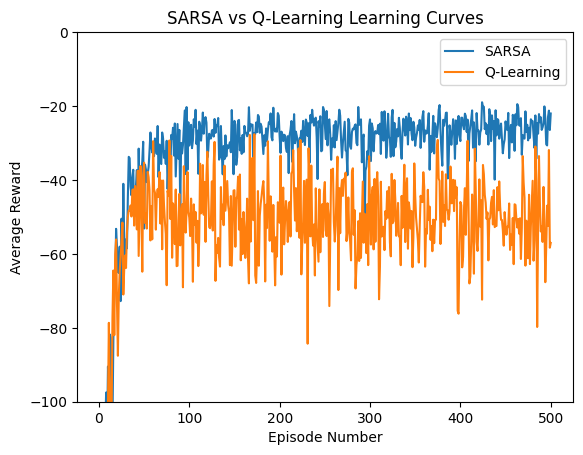

In [7]:
plot_results(sarsa_rewards, q_learning_rewards)

In [8]:
#--- Your code here ---#
def display_policy(Q):
    dir_array = ['↑', '→', '↓', '←']
    arrow_array = np.empty((4,12), str)
    for i in range(len(Q)):
        # get the max state
        arrow_array[int(i/12), i%12] = dir_array[np.argmax(Q[i])]
        if np.max(Q[i]) == 0:
            arrow_array[int(i/12), i%12] = '○'
    # Display it as a 4x12 grid, identifying S, G, and cliff cells.
    # (3,11) is goal, (3,0) is start
    arrow_array[3, 0] = 'S'
    arrow_array[3, 11] = 'G'
    return arrow_array

In [9]:
display_policy(sarsa_Q)

array([['→', '→', '→', '→', '→', '→', '→', '→', '→', '→', '→', '↓'],
       ['↑', '↑', '→', '↑', '↑', '↑', '←', '↑', '↑', '↑', '↑', '↓'],
       ['↑', '←', '→', '↑', '↑', '↑', '↑', '←', '←', '←', '→', '↓'],
       ['S', '○', '○', '○', '○', '○', '○', '○', '○', '○', '○', 'G']],
      dtype='<U1')

In [10]:
display_policy(q_learning_Q)

array([['→', '↓', '↓', '→', '↓', '↑', '→', '↓', '↓', '→', '→', '↓'],
       ['→', '→', '→', '→', '→', '→', '→', '→', '→', '↓', '→', '↓'],
       ['→', '→', '→', '→', '→', '→', '→', '→', '→', '→', '→', '↓'],
       ['S', '○', '○', '○', '○', '○', '○', '○', '○', '○', '○', 'G']],
      dtype='<U1')

Answer the following questions:

(e).1. **Learning performance (10 Points):** Which algorithm achieves higher average episode rewards during training? Explain why.
> Answer</br>
SARSA achieves higher average episode reward during the training. Both algorithms implement an $\epsilon$-greedy algorithm. The difference can be due to how SARSA and Q-learning update their Q-tables. SARSA learns to avoid the edge due to the chance of exploring and falling in and opts to take the safer path while Q-Learning takes the shorter, more direct path and falls into the holes more often due to the exploration.

(e).2. **Learned policies (10 Points):** Compare the greedy policies obtained from SARSA and Q-learning. Do they follow different routes to the goal? Explain why the algorithms may learn different policies. 
> Answer</br>
Yes SARSA takes the safer route away from the edge while Q-learning walks along the edge. This could be because SARSA uses the next action gotten from the $epsilon$-greedy policy to udate the Q-table, this means that the Q-table will account for the exploratory actions. Q-learning uses the best available action to update the Q-table, without also adding the chance of exploration which in this case results in the shortest path, even though when we explore we could fall in. 

(e).3. **Policy quality vs. training performance (10 Points):** Does learning the shortest route to the goal necessarily result in higher average rewards during training? Explain your answer by considering the effect of exploration and the difference between the behavior policy and the greedy policy.
> Answer</br>
No, in this senerio it actually results in a lower average reward during training. This is because the sortest path runs along the cliff edge, so there is always a chance of exploring and falling into the hole. The behavior policy we implement is $\epsilon$-greedy so there will be a chance to go and try a different direction even if there is a hole, thus getting a large reduction in points. If we were to use a pure greedy policy, then the shortest path would result in a higher average as we would not explore into a hole, and thus take the least amount of steps.




## Part II(*): Maximization Bias and Double Q-learning (100 Points)

In this part, you will investigate **maximization bias** in Q-learning and compare its behavior with **Double Q-learning**, as discussed in Section 6.7 of the textbook. The objective is to investigate how the two algorithms estimate action values and how these estimates affect their learning performance.

### Environment: Stochastic Gridworld

The environment consists of a $3\times3$ grid. The agent starts in the bottom-left corner ($S$) and must reach the goal in the top-right corner ($G$).

The agent can take four actions: up, right, down, and left. Actions that would move the agent outside the grid leave it in the same state.

For every action taken outside the goal state, the agent receives a stochastic reward:

$$
R =
\begin{cases}
+10 & \text{with probability } 0.5,\\
-12 & \text{with probability } 0.5.
\end{cases}
$$

The expected reward for these transitions is $-1$.

**Important:** Reaching the goal does not immediately terminate the episode. Once the agent reaches the goal, it must take one additional action. This action produces a reward of $+5$ and terminates the episode.

After termination, a new episode begins at the starting state, while the learned action values are preserved.

The optimal policy follows a shortest path to the goal. The optimal expected average reward per step is $0.2$, and the optimal discounted value of the starting state is approximately $0.36$ when $\gamma=0.95$.


### Experimental Setup

Use the following parameters for both algorithms:

| Parameter | Value |
|---|---|
| Discount factor | $\gamma=0.95$ |
| Initial action values | $Q_0(s,a)=0$ |
| Learning rate | $\alpha(s,a)=1/n(s,a)^{0.8}$ |
| Exploration probability | $\varepsilon(s)=1/\sqrt{n(s)}$ |
| Learning steps per run | 10,000 |
| Independent runs | 100 |

Here, $n(s)$ denotes the number of visits to state $s$, and $n(s,a)$ denotes the number of updates to the corresponding state-action value.

Use the following conventions:

- Increment visitation counters before calculating the corresponding exploration probability or learning rate.
- Preserve Q-values and visitation counters across episodes within each run.
- Reset all Q-values and visitation counters at the beginning of each independent run.
- Break ties between equally valued greedy actions uniformly at random.
- For Double Q-learning, maintain separate learning-rate counters for the two Q-tables.
- Use the sum of the two Q-tables for $\varepsilon$-greedy action selection in Double Q-learning, as described in Section 6.7 of the textbook.
- Randomly select which Q-table to update with equal probability at each learning step.
- When multiple actions maximize the Q-values in the table used for action selection during a Double Q-learning update, use the average of their values from the other Q-table to calculate the TD target.
- Do not bootstrap from terminal transitions. In other words, for terminal transitions, the TD target is simply the received reward, $R_{t+1}$, since there are no future rewards to consider.

Each independent run consists of 10,000 learning steps (agent-environment interactions), potentially spanning multiple episodes. When an episode terminates, restart the environment at the starting state and continue learning with the existing Q-values and visitation counters until all 10,000 steps are completed.

Below, we have provided the transition function for the environment.

In [11]:
import numpy as np

SIDE = 3
START = 6  # Bottom-left, row-major
GOAL = 2   # Top-right

# Actions: 0=Up, 1=Right, 2=Down, 3=Left
MOVES = ((-1, 0), (0, 1), (1, 0), (0, -1))


def transition(state, action, rng):
    """Return (next_state, reward, terminated)."""

    if state == GOAL:
        return START, 5.0, True

    row, col = divmod(state, SIDE)
    dr, dc = MOVES[action]

    row = np.clip(row + dr, 0, SIDE - 1)
    col = np.clip(col + dc, 0, SIDE - 1)

    next_state = int(row * SIDE + col)
    reward = -12.0 if rng.random() < 0.5 else 10.0

    return next_state, reward, False


### (a) Implementation (30 Points)

Implement Double Q-learning following Section 6.7 of the textbook and adapt your Q-learning implementation from Part I to work with the stochastic gridworld.

Both algorithms should use the parameters and conventions specified above and return the learned Q-table(s) and the information needed for the subsequent experiments.

You may use the function structure provided below, but feel free to add functions or classes.

In [12]:
# What we would need for a fake env: 
#   .action_space.n
#   .observation_space.n
#   .reset()
#   .step()

class StochasticGridworldQuasiEnv:
    def __init__(self):
        self.action_space = gym.spaces.Discrete(4)
        self.observation_space = gym.spaces.Discrete(3*3)
        self.current_state = 6

    def __transition(self, state, action):
        """Return (next_state, reward, terminated)."""
        SIDE = 3
        START = 6  # Bottom-left, row-major
        GOAL = 2   # Top-right
    
        # Actions: 0=Up, 1=Right, 2=Down, 3=Left
        MOVES = ((-1, 0), (0, 1), (1, 0), (0, -1))
    
        if state == GOAL:
            return START, 5.0, True

        row, col = divmod(state, SIDE)
        dr, dc = MOVES[action]

        row = np.clip(row + dr, 0, SIDE - 1)
        col = np.clip(col + dc, 0, SIDE - 1)

        next_state = int(row * SIDE + col)
        reward = -12.0 if np.random.random() < 0.5 else 10.0

        return next_state, reward, False

    def reset(self):
        """Return (start_state, info = none)."""
        self.current_state = 6
        return self.current_state, None

    def step(self,action):
        """Return (next_state, reward, terminated, truncated = False, info = none)."""
        next_state, reward, terminated = self.__transition(self.current_state, action)
        self.current_state = next_state
        return next_state, reward, terminated, False, None

# Lets also make the fuctions for \epsilon and \alpha
def epsilon(num_visit):
    return 1/(np.sqrt(num_visit))

def alpha(num_update):
    return 1/(num_update**(0.8))

# Implement the policy (\epsilon-greedy)
def epsilon_greedy(epsilon: float, Q: np.ndarray[float], S: int):
    probability = np.random.uniform(size = 1)

    if probability < epsilon:
        return int(np.random.choice(np.linspace(0, len(Q[S])-1, len(Q[S]))))
    else:
        # Get argmax_a(Q(S,a))
        return argmax(Q[S])

# Make my own argmax that breaks ties randomly
def argmax(a):
    if len(np.argwhere(a == np.max(a)). flatten()) > 1:
        # If there is a tie, choose a random argmax
        action = int(np.random.choice(np.argwhere(a == np.max(a)).flatten()))
    # If no ties then take the argmax
    else: action = int(np.argmax(a))
    return action

def double_q_learning_TD_adjust(a,b):
    if len(np.argwhere(b == np.max(b)). flatten()) > 1:
            # If there is a tie, average out the b's
            a_avg = 0
            indecies = np.argwhere(b == np.max(b)).flatten()
            for index in indecies:
                a_avg += a[index]
            a_avg = a_avg/len(indecies)
            return a_avg
        # If no ties then take the argmax
    else: return a[int(np.argmax(b))]

In [13]:
def double_q_learning_gridworld(env, gamma=0.95, num_episodes=10000):
    # Implement Double Q-learning using the specified
    
    # Initialize Q1(s,a) and Q2(s,a) for all s \in S^+, a \in A(s) arbitrarily except that Q(terminal,\cdot)=0
    num_actions = env.action_space.n
    num_states = env.observation_space.n
    num_learning_steps = 0
    Q1 = np.zeros((num_states,num_actions), float)
    Q2 = np.zeros((num_states,num_actions), float)
    total_rewards = np.zeros(0)
    total_max_Q = np.zeros(0)
    ns = np.zeros(num_states, int)
    nsa1 = np.zeros((num_states, num_actions), int)
    nsa2 = np.zeros((num_states, num_actions), int)
    total_reward = 0

    # Loop for each episode
    while num_learning_steps < num_episodes:

        # Initialize S
        S, info = env.reset()

        # Update the visit count
        ns[S] += 1

        terminated, truncated = (0,0)

        # Loop for each step of episode
        while not(terminated or truncated) and num_learning_steps < num_episodes:
            # Choose A from S using policy derived from Q (e.g., \epsilon-greedy)
            A = epsilon_greedy(epsilon(ns[S]), Q1+Q2, S)

            # Take action A, observe R, S'
            num_learning_steps += 1
            Sp, reward, terminated, truncated, info = env.step(A)

            Q_func = lambda QA, QB, NSA, S, A, Sp, a: QA[S, A] + alpha(NSA[S, A])*(reward + a*gamma*double_q_learning_TD_adjust(QB[Sp], QA[Sp]) - QA[S, A])
            
            # Q(S,A) <- Q(S,A) + \alpha[R + \gamma max_a(Q(S',a)) - Q(S,A)]
            probability = np.random.uniform(size=1)
            if not(terminated or truncated):
                if probability < .5:
                    # Update state action count
                    nsa1[S,A] += 1
                    # Q1(S,A) <- Q1(S,A) + \alpha[R + \gamma Q2(S',argmax_a(Q1(S',a))) - Q1(S,A)]
                    Q1[S, A] = Q_func(Q1,Q2,nsa1,S,A,Sp,1)
                else:
                    # Update state action count
                    nsa2[S,A] += 1
                    Q2[S, A] = Q_func(Q2,Q1,nsa2,S,A,Sp,1)
                # Update the visit count
                ns[Sp] += 1
            else:
                if probability < .5:
                    # Update state action count
                    nsa1[S,A] += 1
                    Q1[S, A] = Q_func(Q1,Q2,nsa1,S,A,Sp,0)
                else:
                    # Update state action count
                    nsa2[S,A] += 1
                    Q2[S, A] = Q_func(Q2,Q1,nsa2,S,A,Sp,0)

            total_reward += reward

            # S <- S'
            S = Sp

            if num_learning_steps%100 == 0:
                # Only grab data at every 100 steps
                total_max_Q = np.append(total_max_Q, np.max(Q1[START]))
                total_rewards = np.append(total_rewards, total_reward/100)
                total_reward = 0


    # Return the final Q-table and episode rewards.
    return (Q1,Q2),total_max_Q, total_rewards

In [14]:
def q_learning_gridworld(env: gym.Env, gamma=0.95, num_episodes=10000) -> tuple[np.ndarray[float], np.ndarray[float]]:
    # Implement Q-learning.

    # Initialize Q(s,a) for all s \in S^+, a \in A(s) arbitrarily except that Q(terminal,\cdot)=0
    num_actions = env.action_space.n
    num_states = env.observation_space.n
    num_learning_steps = 0
    Q = np.zeros((num_states,num_actions), float)
    total_rewards = np.zeros(0)
    total_max_Q = np.zeros(0)
    ns = np.zeros(num_states, int)
    nsa = np.zeros((num_states, num_actions), int)
    total_reward = 0

    # Loop for each episode
    while num_learning_steps < num_episodes:

        # Initialize S
        S, info = env.reset()

        # Update the visit count
        ns[S] += 1

        terminated, truncated = (0,0)

        # Loop for each step of episode
        while not(terminated or truncated) and num_learning_steps < num_episodes:
            # Choose A from S using policy derived from Q (e.g., \epsilon-greedy)
            A = epsilon_greedy(epsilon(ns[S]), Q, S)

            # Update state action count
            nsa[S,A] += 1

            # Take action A, observe R, S'
            num_learning_steps += 1
            Sp, reward, terminated, truncated, info = env.step(A)

            
            # Q(S,A) <- Q(S,A) + \alpha[R + \gamma max_a(Q(S',a)) - Q(S,A)]
            if not(terminated or truncated):
                Q[S, A] = Q[S, A] + alpha(nsa[S,A])*(reward + gamma*(np.max(Q[Sp]))- Q[S, A])
                # Update the visit count
                ns[Sp] += 1
            else:
                Q[S, A] = Q[S, A] + alpha(nsa[S,A])*(reward - Q[S, A])

            total_reward += reward

            # S <- S'
            S = Sp

            if num_learning_steps%100 == 0:
                # Only grab data at every 100 steps
                total_max_Q = np.append(total_max_Q, np.max(Q[START]))
                total_rewards = np.append(total_rewards, total_reward/100)
                total_reward = 0


    # Return the final Q-table and episode rewards.
    return Q,total_max_Q, total_rewards

### (b) Experimental Comparison (40 Points)

Run Q-learning and Double Q-learning for 100 independent runs of 10,000 learning steps each, using the parameters specified above.

Average the results across independent runs and generate the following two plots:

1. **Value estimation:** Plot the estimated maximum action value at the starting state against the number of learning steps, recording values every 100 steps. For Q-learning, use $\max_a Q(S,a)$; for Double Q-learning, use $\max_a Q^A(S,a)$. Include a horizontal reference line at the optimal value, $V^*(S)\approx 0.36$.

2. **Learning performance:** Plot the average reward per learning step against the number of learning steps, using nonoverlapping blocks of 100 steps. Include a horizontal reference line at the optimal expected average reward per step, $0.2$.

Display both algorithms in each figure, with appropriate axis labels, legends, and titles. Adjust the vertical axis limits where necessary to make the differences apparent.

In [15]:
env = StochasticGridworldQuasiEnv()

In [16]:
#--- Your code here ---#
def run_experiments(num_runs=100, num_steps=10000):
    START = 6
    q_Qs = np.zeros((num_runs, int(num_steps/100)), float)
    q_Rs = np.zeros((num_runs, int(num_steps/100)), float)
    q_Qs_avg = np.zeros(int(num_steps/100), float)
    q_Rs_avg = np.zeros(int(num_steps/100), float)
    qq_Qs = np.zeros((num_runs, int(num_steps/100)), float)
    qq_Rs = np.zeros((num_runs, int(num_steps/100)), float)
    qq_Qs_avg = np.zeros(int(num_steps/100), float)
    qq_Rs_avg = np.zeros(int(num_steps/100), float)
    # Run both algorithms and collect the experimental results.
    for i in range(num_runs):
        _,q_Q, q_R = q_learning_gridworld(env, gamma =.95, num_episodes=num_steps)
        _,qq_Q, qq_R = double_q_learning_gridworld(env, gamma =.95, num_episodes=num_steps)
        q_Rs[i] = q_R
        q_Qs[i] = q_Q
        qq_Rs[i] = qq_R
        qq_Qs[i] = qq_Q
    # Generate the value-estimation and learning-performance plots.
    for i in range(int(num_steps/100)):
        q_Qs_avg[i] = np.average(q_Qs[:,i])
        q_Rs_avg[i] = np.average(q_Rs[:,i])
        qq_Qs_avg[i] = np.average(qq_Qs[:,i])
        qq_Rs_avg[i] = np.average(qq_Rs[:,i])
    steps = np.arange(100, num_steps + 1, 100)
    
    # Plot the rewards
    plt.plot(steps, q_Qs_avg, label='Q-learning')
    plt.plot(steps, qq_Qs_avg, label='Double Q-learning')
    plt.plot(steps, (np.zeros(len(q_Rs_avg)) + 0.36), label='Expected Result')
    # plt.plot(steps, q_learning_avg_rewards, label=r'Q-Learning')
    plt.title("Value estimation")
    plt.xlabel("Learning Steps")
    plt.ylabel("Average Action Value from starting state")
    # plt.xlim(0,0)
    plt.legend()
    plt.show()

    plt.plot(steps, q_Rs_avg, label='Q-learning')
    plt.plot(steps, qq_Rs_avg, label='Double Q-learning')
    plt.plot(steps, (np.zeros(int(num_steps/100)) + 0.2), label='Expected Result')
    # plt.plot(steps, q_learning_avg_rewards, label=r'Q-Learning')
    plt.title("Learning performance")
    plt.xlabel("Learning Steps")
    plt.ylabel("Average Reward per Step")
    plt.legend()
    plt.show()
    pass

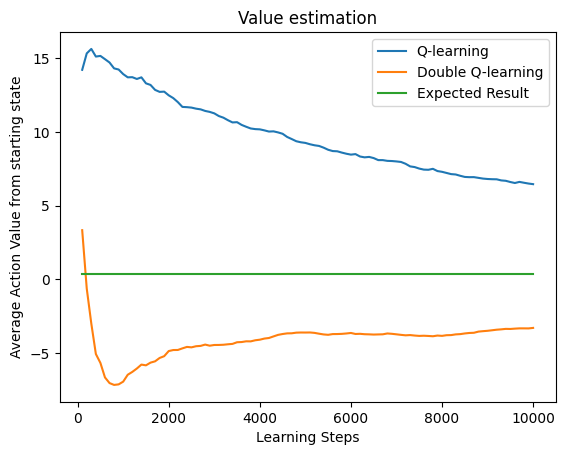

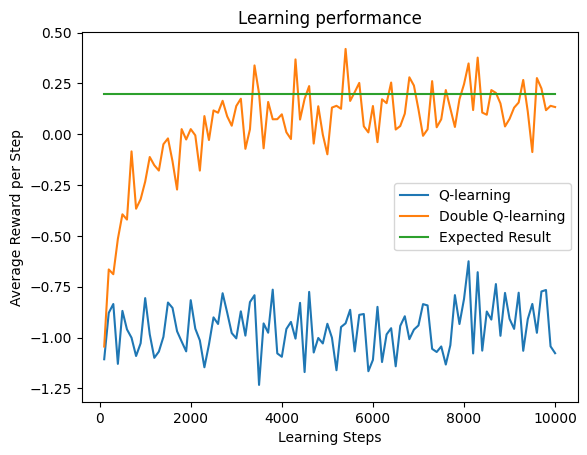

In [17]:
run_experiments(100, 10000)

### (c) Discussion and Analysis (30 Points)

Based on your experimental results, answer the following questions:

1. **Maximization bias (10 Points):** Why does Q-learning tend to overestimate action values in this stochastic environment? Explain how Double Q-learning addresses this problem.

2. **Estimation accuracy (10 Points):** Compare the estimated starting-state values obtained by the two algorithms. Does Double Q-learning necessarily produce more accurate estimates? Explain using your results.

3. **Learning performance (10 Points):** Which algorithm achieves higher average rewards during learning? Explain why an algorithm with less accurate action-value estimates may still achieve better learning performance.

Your answers

(c)1.
> Answer </br> In this enviornment Q-learning is very suseptable to maximization bias. In this scenerio if a not optimal action accurs, and we get a positive reward, the algorithm will favor that action and will keep taking it. This is because the same Q-table is used to evaluate and select the best action. With Double Q-learning, even if we get a positive reward, we have two Q-tables, where the one that selects the next-state action is different from the one that evaluates the next-state action, this helps prevent the algorithm from favoring a stochastic bad action that got a high reward 

(c)2.
> Answer </br> While the error estimation graph shows that Double Q-learning does produce a more accuate estimate, it will not necessarily always be true, Q-learning overestimates the starting value while Double Q-learning underestimates it. Double Q-learning could underestimate the value by a greater amount than Q-learning overestimates it, making its estimate less accurate.

(c)3.
> Answer </br> Double-Q learning achieves higher average rewards. It is possible for an algorithm with less accurate action-value estimates to achieve better learning performance, as having inaccurate value estimates does not mean you are taking an inefficient route, the relative values of the value estimates matter more. If an algorithm with less accurate action-values, has more accurate relative ordering of action values., it will take a more optimal route compared to an algorithm that has more accurate action-values that have a different relative ordering.

## Submission Guide
Submit both your completed notebook (`Homework_5-2026.ipynb`) and your `rl_algorithms.py` file. The notebook must import and use your SARSA and Q-learning implementations from the Python module.